# Exercise 4: storyboard → clips → measure consistency

## Tasks

1. **Plan:** let the OpenAI API draft a short storyboard.
2. **Generate:** create one clip in Google Flow with the character sheet as reference.
3. **Check:** compare the character in the clip with the sheet.

Required: 1 video. No Flow video available? Use Ueli's clip from Exercise 2.

**This is the solution.** Try `video_generation.ipynb` first.

## Setup

Select the **Python 3.11** kernel. The OpenAI API key comes from your `OPENAI_API_KEY` Codespaces secret.

This notebook uses the **OpenAI API** (model `gpt-6-luna`). Other providers, e.g. Google Gemini or Anthropic Claude, have their own APIs with different code. The API calls are in `helper.py` – open it to see how they work.

In [1]:
# Standard Python libraries.
import sys
from pathlib import Path
from typing import Literal

# Libraries installed from requirements.txt.
import pandas as pd
from pydantic import BaseModel

# helper.py is in the main folder, one level up.
sys.path.append("..")

In [2]:
# Functions from helper.py.
from helper import DATA, ask, extract_frames, show_images

## 1. Let the OpenAI API draft a short storyboard

Plan the scenes first, prompt each scene second. The character descriptions stay **exactly the same** in every prompt.

In [3]:
# Fixed descriptions, used in every prompt.
CHARACTER = "Ueli, red beanie, olive jacket"
DOG = "Bruno, Bernese, red collar"

In [4]:
# The answer format: one Flow prompt per scene.
class Storyboard(BaseModel):
    scene_1: str
    scene_2: str
    scene_3: str
    scene_4: str

In [5]:
# The instruction for the model.
PROMPT = f"""
Write four short video prompts for Google Flow, one per scene.
Scene 1: a wide mountain lake without characters.
Scene 2: a drifting boat.
Scene 3: {CHARACTER} together with the dog {DOG}.
Scene 4: sunset.
Each prompt describes shot, camera, action, light and sound.
"""

In [6]:
# Ask for the storyboard. The empty list means: no images.
plan = ask(PROMPT, Storyboard, [])

# Print the four scenes.
for scene in plan:
    print(scene, ":", plan[scene])

scene_1 : Wide establishing shot of a serene mountain lake, no people or animals. The camera slowly glides forward over the water toward distant peaks. Gentle ripples move across the lake in cool morning light. Sound: soft breeze and quiet lapping water.
scene_2 : A small wooden boat drifts across the mountain lake. Track it from a low, side-on camera angle as it turns gently with the current. Soft daylight glints on the ripples. Sound: water against the hull and faint wind.
scene_3 : Ueli, wearing a red beanie and olive jacket, sits beside Bruno, a Bernese dog with a red collar, in the boat. Use a calm medium shot with a slow push-in as Bruno looks toward shore and Ueli smiles. Warm natural light, subtle reflections on the water. Sound: quiet lapping water, a soft breeze, and Bruno’s gentle panting.
scene_4 : The sun sets behind the mountain lake in a wide, still composition. The camera slowly pulls back as golden reflections deepen into amber and rose across the water. Sound: soft ev

In [7]:
# The Flow prompt for scene 3, with the fixed descriptions in front.
scene_3 = plan["scene_3"]
print(f"{CHARACTER}. {DOG}. {scene_3}")

Ueli, red beanie, olive jacket. Bruno, Bernese, red collar. Ueli, wearing a red beanie and olive jacket, sits beside Bruno, a Bernese dog with a red collar, in the boat. Use a calm medium shot with a slow push-in as Bruno looks toward shore and Ueli smiles. Warm natural light, subtle reflections on the water. Sound: quiet lapping water, a soft breeze, and Bruno’s gentle panting.


## 2. Create one clip in Flow with the character sheet

Use **Veo 3.1 Lite**, 8 seconds and **Ingredients to Video**. Add `ueli_sheet.jpg` as ingredient and paste the prompt above. Upload the clip as `my_scene.mp4` next to this notebook.

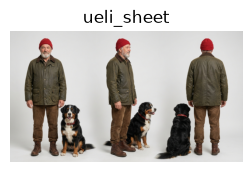

In [8]:
# The character sheet.
sheet = DATA / "reference" / "ueli_sheet.jpg"
show_images([sheet])

In [9]:
# Use your own clip. If there is none, use Ueli's clip from Exercise 2.
video_path = Path("my_scene.mp4")
if not video_path.exists():
    video_path = DATA / "videos" / "ueli_scene3_talk.mp4"
print("Using", video_path.name)

Using ueli_scene3_talk.mp4


## 3. Compare the character in the clip with the sheet

One frame per second is compared with the character sheet.

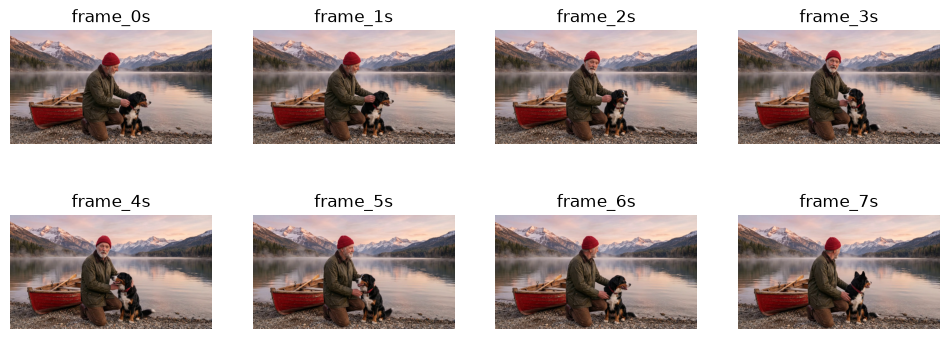

In [10]:
# Save one frame per second of the clip and show them.
paths = extract_frames(video_path)
show_images(paths)

In [11]:
# The three allowed ratings.
Rating = Literal["match", "differs", "not visible"]


# The answer format: one rating per feature.
class Consistency(BaseModel):
    beanie: Rating
    jacket: Rating
    dog: Rating

In [12]:
# The instruction: compare image 2 with the reference image 1.
PROMPT = """
Image 1 is the reference.
Rate the beanie, the jacket and the dog in image 2.
Use match for a visible match.
Use differs for a visible change.
Use not visible when it is unclear or out of frame.
"""

In [13]:
# Compare every frame with the sheet. The sheet comes first.
rows = []
for path in paths:
    row = ask(PROMPT, Consistency, [sheet, path])
    row["frame"] = path.name
    rows.append(row)

# One row per frame.
ratings = pd.DataFrame(rows)
ratings

,beanie,jacket,dog,frame
0,match,match,match,frame_0s.jpg
1,match,match,match,frame_1s.jpg
2,match,match,match,frame_2s.jpg
3,match,match,match,frame_3s.jpg
4,match,match,match,frame_4s.jpg
5,match,match,match,frame_5s.jpg
6,match,match,match,frame_6s.jpg
7,match,match,match,frame_7s.jpg


In [14]:
# Count the frames that match the sheet, per feature.
for feature in ["beanie", "jacket", "dog"]:
    matches = (ratings[feature] == "match").sum()
    print(feature, ":", matches, "of", len(ratings), "frames match")

beanie : 8 of 8 frames match
jacket : 8 of 8 frames match
dog : 8 of 8 frames match


## Check your understanding

Answer briefly using the outputs above. Try first, then open the hints.

1. If every frame were generated as a separate image, the video would flicker (details jump from frame to frame). Why – and how do video models avoid it?
2. Why do we use exactly the same character description in every prompt, together with the character sheet?
3. Which feature matched least often in your clip? Look at these frames: is the character really different, or is the feature just not visible?
4. The ratings come from a model. How would you check whether you can trust them?
5. Why is the number of matching frames a better result than "the clip looks fine"?

**Your answers:**

1. …
2. …
3. …
4. …
5. …

<details>
<summary style="color: #B8860B; font-weight: bold; cursor: pointer;">Hints for self-check</summary>

1. Every image starts from new random noise, so details like the face or the clothes come out differently each time. Video models generate all frames together, across space and time. That keeps the details stable.

2. Small changes in the wording can produce a different person or dog. The same text plus the same reference image anchor the identity across scenes.

3. Use your table. `not visible` is not an error of the video: Ueli may be turned away or out of frame. Only `differs` shows that the character has changed.

4. Rate a few frames yourself and compare them with the ratings of the model. Where you and the model disagree, the model is not reliable.

5. A number can be compared between clips, prompts and settings, and other people can repeat the measurement. An impression cannot be compared.

</details>

### Jupyter notebook --footer info--

In [15]:
# Print system and version info for this run.
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1070-azure
Datetime: 2026-11-23 16:47:44
Python Version: 3.11.18
-----------------------------------
